# Receding-horizon control of a noisy unicycle

The robot must reach $(3,2)$ m facing north. Every 0.1 s it plans three seconds of motion, applies the first control, and measures its disturbed pose. Comparing horizon predictions with the executed path shows how feedback changes the plan. [C++ example](https://github.com/borglab/gtsam/blob/develop/gtsam_unstable/examples/mppi/UnicycleMPPIMPCExample.cpp)

GTSAM Copyright 2010-2026, Georgia Tech Research Corporation,
Atlanta, Georgia 30332-0415

All Rights Reserved

Authors: Akash Ratheesh and Frank Dellaert (see THANKS for the full author list)

See LICENSE for the license information

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/borglab/gtsam/blob/develop/python/gtsam_unstable/examples/planning/UnicycleMPPIMPCExample.ipynb)

In [1]:
try:
    import google.colab
    %pip install --quiet gtsam-develop plotly==6.3.1
except ImportError:
    pass

In [2]:
from html import escape
import numpy as np
import gtsam
import gtsam_unstable as unstable
from gtsam.symbol_shorthand import U, X
from plotly.subplots import make_subplots
from IPython.display import HTML, display

teal, orange = "#087B78", "#B65025"
plotly_js = "https://cdn.plot.ly/plotly-3.1.1.min.js"

## Build the fixed objective

The pose and control priors use the same weights as the open-loop example. Every candidate follows `Unicycle.predict`, which satisfies the model's hard transition factors at each step. Their contribution is zero, so the reusable scoring graph needs only the priors.

In [3]:
H, dt = 30, 0.1
state_keys = [X(k) for k in range(H + 1)]
control_keys = [U(k) for k in range(H)]
model = unstable.Unicycle(dt)
start, goal = gtsam.Pose2(), gtsam.Pose2(3., 2., np.pi / 2)
running = gtsam.noiseModel.Diagonal.Precisions(np.array([1., 1., 0.1]))
terminal = gtsam.noiseModel.Diagonal.Precisions(np.array([100., 100., 10.]))
effort = gtsam.noiseModel.Isotropic.Precision(2, 0.1)

graph = gtsam.NonlinearFactorGraph()
for k, key in enumerate(control_keys):
    graph.add(gtsam.PriorFactorVector(key, np.zeros(2), effort))
    graph.add(gtsam.PriorFactorPose2(state_keys[k + 1], goal, terminal if k == H - 1 else running))

## Reuse the planner, proposal, and update rule

The planner holds the horizon keys. At each decision MPPI uses 1,024 sampled control sequences to refine the nominal plan with one update. The same seeded proposal supplies fresh draws for successive decisions.

In [4]:
planner = gtsam.SamplingPlannerPose2Vector(state_keys, control_keys, dt)
proposal = gtsam.GaussianProposal(0.25 * np.eye(2), 1024, 42)
rule = gtsam.MPPI(1.0)
dynamics = unstable.unicycleTransition(model)

The simulator applies the first speed and yaw-rate command, then retracts a Gaussian disturbance in the robot's own frame. Its per-step standard deviations are 0.01 m, 0.01 m, and 0.01 rad. Shifting the remaining commands one step earlier and appending zero supplies a warm start for the next measurement.

In [5]:
noise = gtsam.Sampler(np.full(3, 0.01), 42)
position_tol, heading_tol = 0.05, 0.1
pose, nominal = start, np.zeros((2, H))
poses, forecasts = [start], []

def errors(pose):
    return (np.linalg.norm(pose.translation() - goal.translation()),
            abs(goal.rotation().between(pose.rotation()).theta()))

for step in range(100):
    distance, heading = errors(pose)
    if distance < position_tol and heading < heading_tol:
        break
    seed = gtsam.Values()
    seed.insert(X(0), pose)
    initial = planner.rollout(seed, nominal, dynamics)
    plan = planner.optimize(graph, initial, dynamics, proposal, rule, 1)
    if step % 10 == 0:  # Save one forecast per second for the figure.
        forecasts.append([plan.atPose2(key).translation() for key in state_keys])
    controls = planner.nominalControls(plan)
    pose = model.predict(pose, controls[:, 0]).retract(noise.sample())
    poses.append(pose)
    nominal = np.column_stack([controls[:, 1:], np.zeros(2)])

time = dt * np.arange(len(poses))
path = np.array([p.translation() for p in poses])
residual = np.array([errors(p) for p in poses])
reached = residual[-1, 0] < position_tol and residual[-1, 1] < heading_tol
print(f"{'Reached goal' if reached else 'Time limit'} at {time[-1]:.1f} s")
print(f"Final distance {residual[-1, 0]:.4f} m, heading error {residual[-1, 1]:.4f} rad")

Reached goal at 4.1 s
Final distance 0.0171 m, heading error 0.0844 rad


## Compare predictions with execution

The gray curves show the full three-second forecast made at each whole second. The teal path records the disturbed robot. The simulation stops on the first tick when **both** error traces are below their dashed thresholds, or after 10 s. Interactive figures require an internet connection.

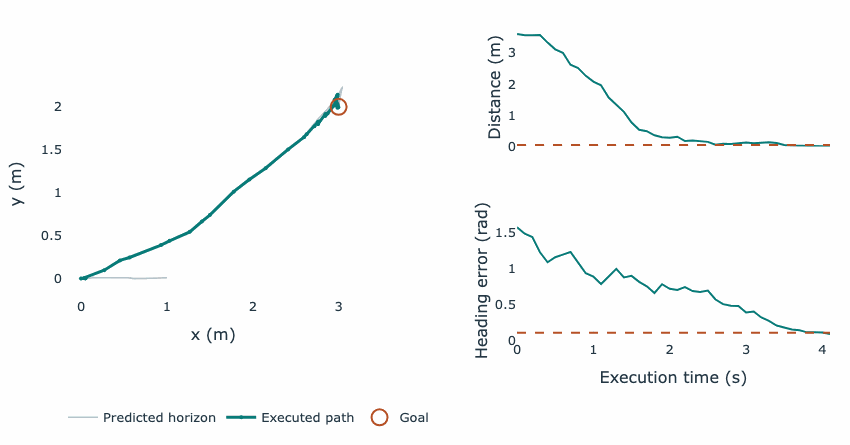

In [6]:
fig = make_subplots(rows=2, cols=2, specs=[[{"rowspan": 2}, {}], [None, {}]],
                    column_widths=[0.49, 0.51], horizontal_spacing=0.20, vertical_spacing=0.24)
for second, forecast in enumerate(forecasts):
    xy = np.array(forecast)
    fig.add_scatter(x=xy[:, 0], y=xy[:, 1], mode="lines",
                    name="Predicted horizon", showlegend=(second == 0), legendgroup="horizons",
                    line=dict(color="#B6C1CB", width=1.5),
                    hovertemplate=f"Forecast at {second} s<extra></extra>", row=1, col=1)
fig.add_scatter(x=path[:, 0], y=path[:, 1], mode="lines+markers", name="Executed path",
                line=dict(color=teal, width=3), marker_size=4, customdata=time,
                hovertemplate="%{customdata:.1f} s · (%{x:.2f}, %{y:.2f}) m<extra></extra>", row=1, col=1)
fig.add_scatter(x=[goal.x()], y=[goal.y()], mode="markers", name="Goal",
                marker=dict(symbol="circle-open", size=16, color=orange, line_width=2), row=1, col=1)
for row, title, tol in [(1, "Distance (m)", position_tol), (2, "Heading error (rad)", heading_tol)]:
    fig.add_scatter(x=time, y=residual[:, row - 1], mode="lines", name=title,
                    line=dict(color=teal), showlegend=False, row=row, col=2)
    fig.add_hline(y=tol, line=dict(dash="dash", color=orange), row=row, col=2)
    fig.update_yaxes(title_text=title, title_standoff=3, rangemode="tozero", row=row, col=2)
fig.update_xaxes(title_text="x (m)", row=1, col=1)
fig.update_yaxes(title_text="y (m)", scaleanchor="x", scaleratio=1, constrain="domain", row=1, col=1)
fig.update_xaxes(matches="x3", showticklabels=False, row=1, col=2)
fig.update_xaxes(title_text="Execution time (s)", row=2, col=2)
fig.update_layout(template="plotly_white", height=445, margin=dict(l=63, r=20, t=28, b=65),
                  font=dict(size=13, color="#243744"), hoverlabel=dict(namelength=-1),
                  legend=dict(orientation="h", y=-0.20, x=0))
# Give Plotly its own document so the figure also runs in the published guide.
plot = fig.to_html(full_html=False, include_plotlyjs=plotly_js,
                   config={"displaylogo": False, "responsive": True})
document = '<!doctype html><meta charset="utf-8"><style>body{margin:0}</style>' + plot
display(HTML(f'<iframe title="Receding-horizon control of a noisy unicycle" style="width:100%;border:0" '
             f'height="{fig.layout.height}" srcdoc="{escape(document, quote=True)}"></iframe>'))